<a href="https://colab.research.google.com/github/m4rtin1/text_summarization/blob/main/text_summarization_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Loading the Dataset

In [1]:
from datasets import load_dataset

ds = load_dataset("abisee/cnn_dailymail", "3.0.0")

README.md:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

3.0.0/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

3.0.0/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

3.0.0/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  259MB            

... (4 outputs left out)

3.0.0/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/287113 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/13368 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/11490 [00:00<?, ? examples/s]

## Dataset to DataFrame Conversion

In [2]:
import pandas as pd

df_train = ds["train"].to_pandas()
df_val = ds["validation"].to_pandas()
df_test = ds["test"].to_pandas()

df = pd.concat([df_train, df_val, df_test], ignore_index=True)

## Dropping Unnecessary Columns

In [3]:
df_train.drop(columns=["id"], inplace=True)
df_val.drop(columns=["id"], inplace=True)
df_test.drop(columns=["id"], inplace=True)

df.drop(columns=["id"], inplace=True)

# Dataset Overview

## Inspecting The Data

In [4]:
print("Number of training examples:", df_train.shape[0])
print("Number of validation examples:", df_val.shape[0])
print("Number of testing examples:", df_test.shape[0])
print()
print("Total number of examples:", df.shape[0])

Number of training examples: 287113
Number of validation examples: 13368
Number of testing examples: 11490

Total number of examples: 311971


In [5]:
print("Number of duplicates in traning set:", df_train.duplicated().sum())
print("Number of duplicates in validation set:", df_val.duplicated().sum())
print("Number of duplicates in testing set:", df_test.duplicated().sum())
print()
print("Number of duplicates in entire dataset:", df.duplicated().sum())

Number of duplicates in traning set: 3098
Number of duplicates in validation set: 0
Number of duplicates in testing set: 2

Number of duplicates in entire dataset: 3101


In [6]:
df_train.drop_duplicates(inplace=True, keep="first")
df_test.drop_duplicates(inplace=True, keep="first")
df_val.drop_duplicates(inplace=True, keep="first")

df.drop_duplicates(inplace=True, keep="first")

In [7]:
print("Number of examples after removing duplicates")

print("Number of training examples:", df_train.shape[0])
print("Number of validation examples:", df_val.shape[0])
print("Number of testing examples:", df_test.shape[0])
print()
print("Total number of examples:", df.shape[0])

Number of examples after removing duplicates
Number of training examples: 284015
Number of validation examples: 13368
Number of testing examples: 11488

Total number of examples: 308870


## Article and Summary Analysis

In [8]:
# length = number of words including space
# chars = number of characters

df["article_length"] = df["article"].apply(lambda x: len(x.split()))
df["article_chars"] = df["article"].str.len()

df["highlights_length"] = df["highlights"].apply(lambda x: len(x.split()))
df["highlights_chars"] = df["highlights"].str.len()

In [9]:
print("Average article length:", round(df["article_length"].mean(), 3))
print("Average article characters:", round(df["article_chars"].mean(), 3))
print()
print("Average summary length:", round(df["highlights_length"].mean(), 3))
print("Average summary characters:", round(df["highlights_chars"].mean(), 3))
print()
print("Maximum article length:", df["article_length"].max())
print("Maximum article characters:", df["article_chars"].max())
print()
print("Maximum summary length:", df["highlights_length"].max())
print("Maximum summary characters:", df["highlights_chars"].max())
print()
print("Minimum article length:", df["article_length"].min())
print("Minimum article characters:", df["article_chars"].min())
print()
print("Minimum summary length:", df["highlights_length"].min())
print("Minimum summary characters:", df["highlights_chars"].min())

Average article length: 691.206
Average article characters: 4027.581

Average summary length: 52.045
Average summary characters: 297.156

Maximum article length: 2347
Maximum article characters: 15925

Maximum summary length: 1440
Maximum summary characters: 8541

Minimum article length: 8
Minimum article characters: 48

Minimum summary length: 4
Minimum summary characters: 14


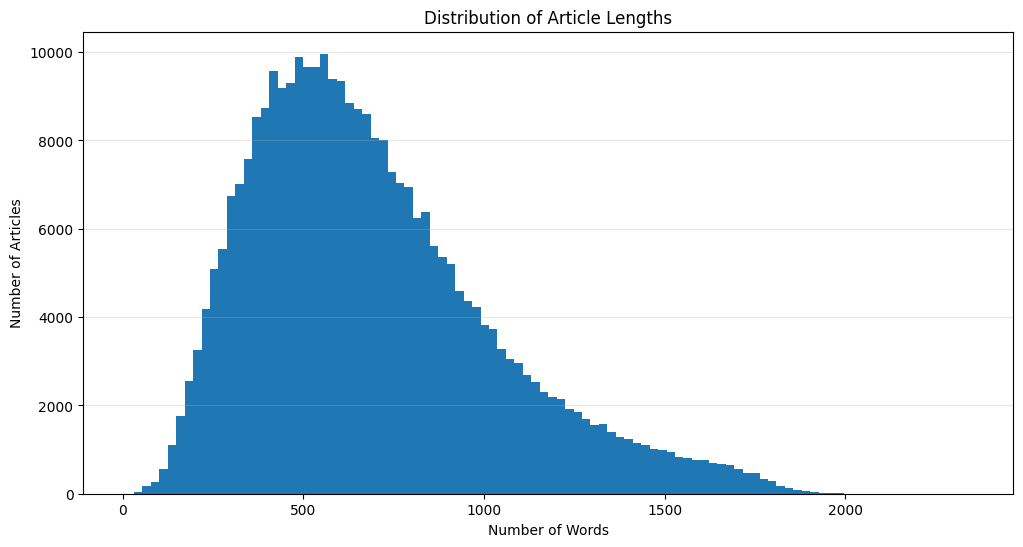

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.hist(df["article_length"], bins=100)
plt.title("Distribution of Article Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Articles")
plt.grid(axis="y", alpha=0.3)

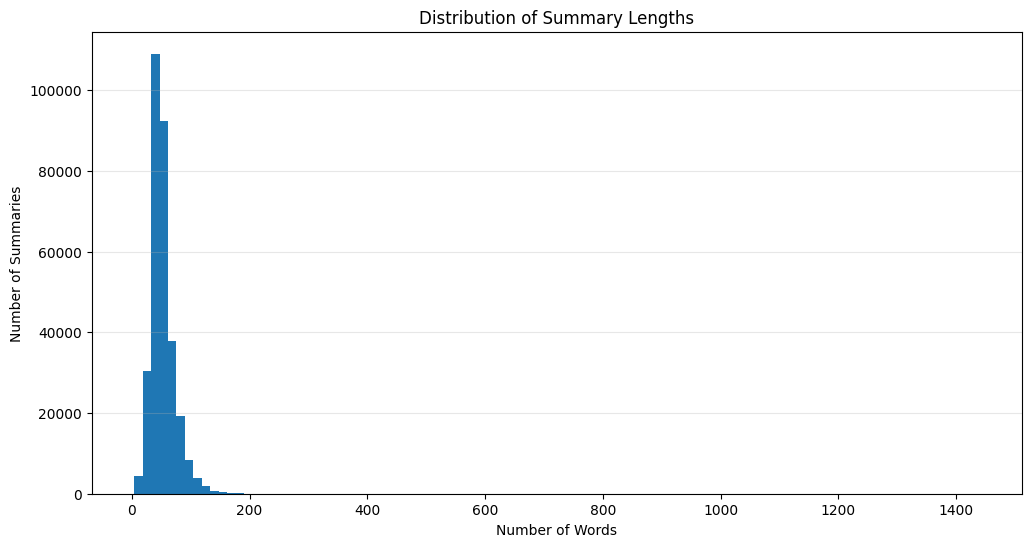

In [11]:
plt.figure(figsize=(12, 6))
plt.hist(df["highlights_length"], bins=100)
plt.title("Distribution of Summary Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Summaries")
plt.grid(axis="y", alpha=0.3)

In [12]:
# CR = Compression Ratio (summary / article)

df["CR_length"] = df["highlights_length"] / df["article_length"]

In [13]:
print("Average compression ratio words:", round(df["CR_length"].mean(), 3))
print("Maximum compression ratio words:", round(df["CR_length"].max(), 3))
print("Minimum compression ratio words:", round(df["CR_length"].min(), 3))

Average compression ratio words: 0.092
Maximum compression ratio words: 19.0
Minimum compression ratio words: 0.005


In [15]:
print(df[df["CR_length"] > 1].shape[0])
print(df[df["CR_length"] < 1].shape[0])
print(df[df["CR_length"] < 0.5].shape[0])
print(df[df["CR_length"] < 0.1].shape[0])
print(df[df["CR_length"] < 0.05].shape[0])
print(df[df["CR_length"] < 0.01].shape[0])

32
308837
308637
205947
59890
163


In [16]:
df.drop(df[df["CR_length"] > 1].index, inplace=True)
df.drop(df[df["CR_length"] < 0.01].index, inplace=True)

In [17]:
print(df[df["CR_length"] > 1].shape[0])
print(df[df["CR_length"] < 1].shape[0])
print(df[df["CR_length"] < 0.5].shape[0])
print(df[df["CR_length"] < 0.1].shape[0])
print(df[df["CR_length"] < 0.05].shape[0])
print(df[df["CR_length"] < 0.01].shape[0])

0
308674
308474
205784
59727
0


## Cleaning Individual Splits

In [18]:
df_train["article_length"] = df_train["article"].apply(lambda x: len(x.split()))
df_train["highlights_length"] = df_train["highlights"].apply(lambda x: len(x.split()))

df_test["article_length"] = df_test["article"].apply(lambda x: len(x.split()))
df_test["highlights_length"] = df_test["highlights"].apply(lambda x: len(x.split()))

df_val["article_length"] = df_val["article"].apply(lambda x: len(x.split()))
df_val["highlights_length"] = df_val["highlights"].apply(lambda x: len(x.split()))

df_train["CR_length"] = df_train["highlights_length"] / df_train["article_length"]
df_test["CR_length"] = df_test["highlights_length"] / df_test["article_length"]
df_val["CR_length"] = df_val["highlights_length"] / df_val["article_length"]

df_train.drop(df_train[df_train["CR_length"] > 1].index, inplace=True)
df_test.drop(df_test[df_test["CR_length"] > 1].index, inplace=True)
df_val.drop(df_val[df_val["CR_length"] > 1].index, inplace=True)

df_train.drop(df_train[df_train["CR_length"] < 0.01].index, inplace=True)
df_test.drop(df_test[df_test["CR_length"] < 0.01].index, inplace=True)
df_val.drop(df_val[df_val["CR_length"] < 0.01].index, inplace=True)

In [20]:
df_train.shape[0] + df_test.shape[0] + df_val.shape[0]

(308676, 308675)

In [48]:
import nltk
from nltk.tokenize import sent_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer

import numpy as np
import random

nltk.download("punkt_tab")
idx = random.randint(0, df_train.shape[0])
article = df_train.iloc[idx]["article"]
summary = df_train.iloc[idx]["highlights"]

sentences = sent_tokenize(article)
print("Number of sentences is first article:", len(sentences))

Number of sentences is first article: 23


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [49]:
vectorizer = TfidfVectorizer(stop_words="english")

tfidf_matrix = vectorizer.fit_transform(sentences)
print(tfidf_matrix.shape)

(23, 205)


In [50]:
word_counts = tfidf_matrix.getnnz(axis=1)

sentence_scores = np.asarray(
    tfidf_matrix.sum(axis=1)
).flatten() / np.maximum(word_counts, 1)

sentence_scores

array([0.27242685, 0.25403331, 0.24888201, 0.70710678, 0.29618585,
       0.25197004, 0.40361029, 0.20982353, 0.27020964, 0.3103353 ,
       0.2002124 , 0.23195421, 0.23234523, 0.26775486, 0.19408437,
       0.40327249, 0.69914299, 0.37331101, 0.23189026, 0.14851559,
       0.17171978, 0.5       , 0.43091224])

In [51]:
results = pd.DataFrame({
    "sentence_id": range(len(sentences)),
    "sentence": sentences,
    "score": sentence_scores
})

results = results.sort_values(
    by="score",
    ascending=False
)

results

,sentence_id,sentence,score
3,3,Scroll down for audio .,0.707107
16,16,Last October she tweeted: .,0.699143
21,21,The settlement reportedly cost him £8 million.,0.500000
22,22,Terfel and Stone’s agent was unavailable for c...,0.430912
6,6,"A source close to the harpist said: ‘Yes, they...",0.403610
15,15,"She married Mr Griffiths in 2012, and until re...",0.403272
17,17,‘Really enjoyed Mid Wales Opera’s Albert Herri...,0.373311
9,9,Last month he was seen with Ms Stone at the Fi...,0.310335
4,4,"Hannah Stone, 27, is the official harpist for ...",0.296186
0,0,"Britain's biggest opera star, Bryn Terfel, is ...",0.272427


In [52]:
top_sentences = results.nlargest(5, "score")
top_sentences = top_sentences.sort_values("sentence_id")
top_sentences

,sentence_id,sentence,score
3,3,Scroll down for audio .,0.707107
6,6,"A source close to the harpist said: ‘Yes, they...",0.403610
16,16,Last October she tweeted: .,0.699143
21,21,The settlement reportedly cost him £8 million.,0.500000
22,22,Terfel and Stone’s agent was unavailable for c...,0.430912


In [53]:
summary = " ".join(top_sentences["sentence"])

print(summary)

Scroll down for audio . A source close to the harpist said: ‘Yes, they are seeing each other. Last October she tweeted: . The settlement reportedly cost him £8 million. Terfel and Stone’s agent was unavailable for comment.
